# Manutenção Preditiva na Indústria 4.0

## Fase 1 - Análise Exploratória dos Dados (EDA)

Este notebook tem como objetivo analisar uma base histórica de manutenção industrial para identificar padrões relacionados à ocorrência de falhas em equipamentos.

A variável alvo do projeto é `Falha_maquina`, em que:
- `0` representa funcionamento normal;
- `1` representa ocorrência de falha mecânica. 

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("../data/raw/manutencao_preditiva.csv")

In [5]:
df.head()

,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


In [27]:
df.shape

(10000, 14)

In [28]:
df.describe()

,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00000,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.002158,310.000895,1539.245263,39.974168,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.001689,1.486432,180.273589,9.995453,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1504.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1613.000000,46.700000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [29]:
import matplotlib.pyplot as plt

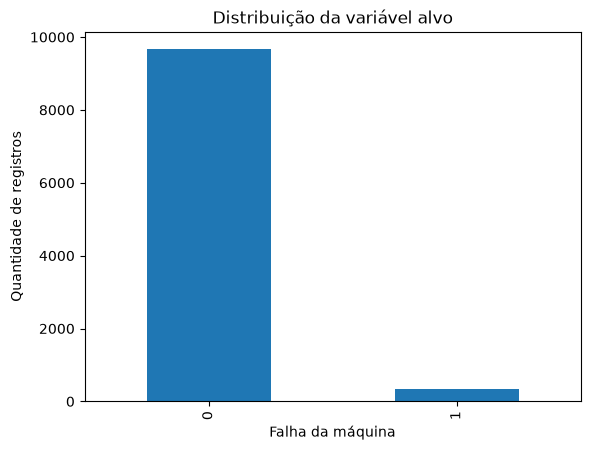

In [30]:
df["falha_maquina"].value_counts().plot(kind="bar")
plt.title("Distribuição da variável alvo")
plt.xlabel("Falha da máquina")
plt.ylabel("Quantidade de registros")
plt.show()

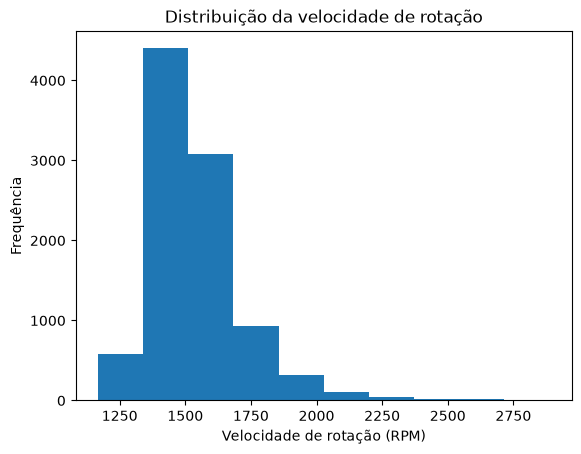

In [31]:
df["velocidade_rotacao_rpm"].plot(kind="hist")
plt.title("Distribuição da velocidade de rotação")
plt.xlabel("Velocidade de rotação (RPM)")
plt.ylabel("Frequência")
plt.show()

Observando o gráfico, percebi que a maior parte dos valores de rotação está concentrada entre aproximadamente 1.400 e 1.700 RPM. Também aparecem alguns valores mais altos, porém em menor quantidade. A distribuição não ficou totalmente simétrica, pois existe uma quantidade menor de registros nas rotações mais elevadas.

In [32]:
correlacao = df[[
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
    "falha_maquina"
]].corr()

In [33]:
correlacao

,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina
temperatura_ar_k,1.000000,0.876601,0.022915,-0.013598,0.011470,0.083090
temperatura_processo_k,0.876601,1.000000,0.019094,-0.013585,0.009928,0.037497
velocidade_rotacao_rpm,0.022915,0.019094,1.000000,-0.875414,-0.000649,-0.040791
torque_nm,-0.013598,-0.013585,-0.875414,1.000000,-0.002557,0.188905
desgaste_ferramenta_min,0.011470,0.009928,-0.000649,-0.002557,1.000000,0.105448
falha_maquina,0.083090,0.037497,-0.040791,0.188905,0.105448,1.000000


In [34]:
import seaborn as sns

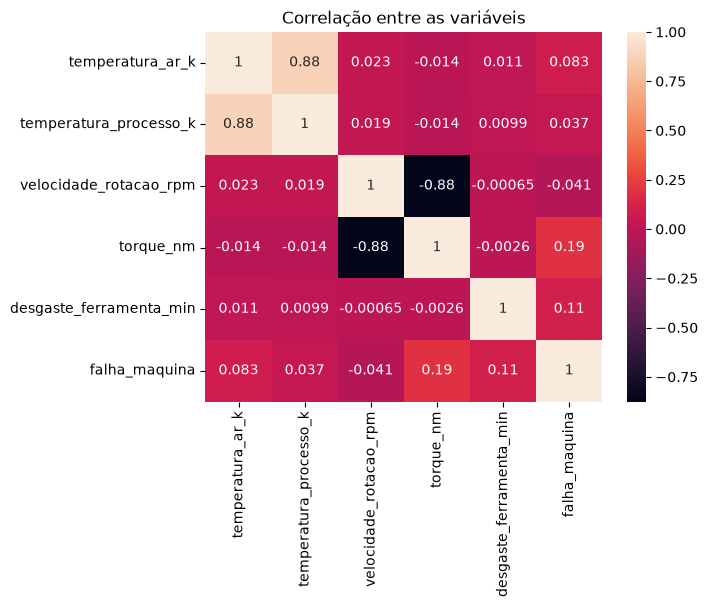

In [35]:
sns.heatmap(correlacao, annot=True)
plt.title("Correlação entre as variáveis")
plt.show()

No mapa de correlação, observei que a temperatura do ar e a temperatura do processo possuem uma relação forte entre si, com valor próximo de 0,88. Também aparece uma relação forte, mas negativa, entre a velocidade de rotação e o torque, próxima de -0,88.

Quando observo a variável falha_maquina, nenhuma das variáveis apresenta uma correlação muito alta sozinha. O torque foi a que apresentou a maior relação positiva com a falha. Isso mostra que provavelmente a falha não depende apenas de uma única variável, mas da combinação entre várias características da máquina.

A base possui 10.000 registros e 14 colunas. Durante a análise, observei que existem valores ausentes em algumas variáveis numéricas, que serão tratados na próxima etapa.

A variável falha_maquina está bastante desbalanceada, com 9.661 registros sem falha e apenas 339 registros com falha. Também percebi que a velocidade de rotação possui maior concentração em valores intermediários e poucos registros em rotações muito altas.

Na análise das correlações, a temperatura do ar e a temperatura do processo apresentaram uma relação forte entre si. A velocidade de rotação e o torque também possuem uma relação forte, porém negativa. Já em relação à falha da máquina, nenhuma variável apresentou uma correlação muito alta sozinha, indicando que será importante analisar a combinação entre as características durante a criação do modelo.